# **1. Data Preprocessing**

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

In [25]:
from google.colab import files
uploaded = files.upload()

Saving Student_Performance.csv to Student_Performance (1).csv


In [26]:
file_name = next(name for name in uploaded if name.endswith(".csv"))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [27]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB

Missing Values:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Duplicate Rows: 127

Statistical Summary:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000,10000.000000,10000.000000,10000.000000
unique,NaN,NaN,2,NaN,NaN,NaN
top,NaN,NaN,No,NaN,NaN,NaN
freq,NaN,NaN,5052,NaN,NaN,NaN
mean,4.992900,69.445700,NaN,6.530600,4.583300,55.224800
std,2.589309,17.343152,NaN,1.695863,2.867348,19.212558
min,1.000000,40.000000,NaN,4.000000,0.000000,10.000000
25%,3.000000,54.000000,NaN,5.000000,2.000000,40.000000
50%,5.000000,69.000000,NaN,7.000000,5.000000,55.000000
75%,7.000000,85.000000,NaN,8.000000,7.000000,71.000000



Column Names:
['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Shape before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())

df["Extracurricular Activities"] = df[
    "Extracurricular Activities"
].map({"Yes": 1, "No": 0})

print("\nCategorical feature encoded successfully.")
display(df.head())

X = df.drop("Performance Index", axis=1)
y = df["Performance Index"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed.")

Shape before removing duplicates: (10000, 6)
Shape after removing duplicates: (9873, 6)
Duplicates remaining: 0

Missing values:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Categorical feature encoded successfully.


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0



Training features shape: (7898, 5)
Testing features shape: (1975, 5)
Training target shape: (7898,)
Testing target shape: (1975,)

Feature scaling completed.


# **2. Model Deployment**

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
training_times = {}

for name, model in models.items():
    start_time = time.time()

    model.fit(X_train_scaled, y_train)

    elapsed_time = time.time() - start_time

    trained_models[name] = model
    training_times[name] = elapsed_time

    print(f"{name} trained successfully!")
    print(f"Training time: {elapsed_time:.4f} seconds\n")

Linear Regression trained successfully!
Training time: 0.0055 seconds

Decision Tree trained successfully!
Training time: 0.0254 seconds

Random Forest trained successfully!
Training time: 1.3300 seconds



# **3. Model Evaluation**

In [30]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Training Time (seconds)": training_times[name],
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print("MODEL EVALUATION RESULTS")
display(results_df.round(4))

MODEL EVALUATION RESULTS


,Model,Training Time (seconds),MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.0055,1.6470,4.3059,2.0751,0.9884
1,Decision Tree,0.0254,2.4196,9.2662,3.0440,0.9751
2,Random Forest,1.3300,1.8975,5.6320,2.3732,0.9849


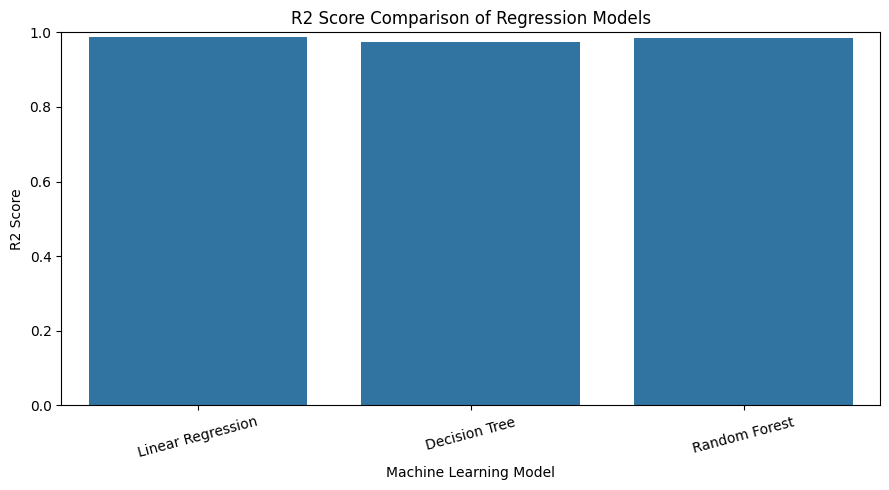

In [31]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("R2 Score Comparison of Regression Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("R2 Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# **Bonus: Hyperparameter Tuning**

In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Decision Tree tuning
dt_params = {
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    dt_params,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

dt_grid.fit(X_train_scaled, y_train)

print("Decision Tree Best Parameters:")
print(dt_grid.best_params_)
print("Best CV RMSE:", np.sqrt(-dt_grid.best_score_))

# Random Forest tuning
rf_params = {
    "n_estimators": [50, 100],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=1),
    rf_params,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

print("\nRandom Forest Best Parameters:")
print(rf_grid.best_params_)
print("Best CV RMSE:", np.sqrt(-rf_grid.best_score_))

Decision Tree Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best CV RMSE: 2.487109988291378

Random Forest Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV RMSE: 2.2368939639973697


In [33]:
tuned_models = {
    "Tuned Decision Tree": dt_grid.best_estimator_,
    "Tuned Random Forest": rf_grid.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test_scaled)

    tuned_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

tuned_results_df = pd.DataFrame(tuned_results)

print("TUNED MODEL RESULTS")
display(tuned_results_df.round(4))

TUNED MODEL RESULTS


,Model,MAE,MSE,RMSE,R2 Score
0,Tuned Decision Tree,1.9802,6.1916,2.4883,0.9834
1,Tuned Random Forest,1.8085,5.1586,2.2713,0.9861


# **4. Model Comparison**

In [34]:
comparison_df = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Training Time (s)": training_times["Linear Regression"],
        "MAE": 1.6470,
        "MSE": 4.3059,
        "RMSE": 2.0751,
        "R2 Score": 0.9884,
        "Advantages": "Fast, simple and interpretable",
        "Limitations": "Assumes a linear relationship"
    },
    {
        "Model": "Decision Tree",
        "Training Time (s)": training_times["Decision Tree"],
        "MAE": 2.4196,
        "MSE": 9.2662,
        "RMSE": 3.0440,
        "R2 Score": 0.9751,
        "Advantages": "Easy to understand, captures nonlinear patterns",
        "Limitations": "Can overfit training data"
    },
    {
        "Model": "Random Forest",
        "Training Time (s)": training_times["Random Forest"],
        "MAE": 1.8975,
        "MSE": 5.6320,
        "RMSE": 2.3732,
        "R2 Score": 0.9849,
        "Advantages": "Ensemble model, reduces variance",
        "Limitations": "Slower and less interpretable"
    },
    {
        "Model": "Tuned Decision Tree",
        "Training Time (s)": np.nan,
        "MAE": 1.9802,
        "MSE": 6.1916,
        "RMSE": 2.4883,
        "R2 Score": 0.9834,
        "Advantages": "Controlled tree complexity",
        "Limitations": "Still less accurate than Linear Regression"
    },
    {
        "Model": "Tuned Random Forest",
        "Training Time (s)": np.nan,
        "MAE": 1.8085,
        "MSE": 5.1586,
        "RMSE": 2.2713,
        "R2 Score": 0.9861,
        "Advantages": "Improved generalization after tuning",
        "Limitations": "More computationally expensive"
    }
])

display(comparison_df.round(4))

,Model,Training Time (s),MAE,MSE,RMSE,R2 Score,Advantages,Limitations
0,Linear Regression,0.0055,1.6470,4.3059,2.0751,0.9884,"Fast, simple and interpretable",Assumes a linear relationship
1,Decision Tree,0.0254,2.4196,9.2662,3.0440,0.9751,"Easy to understand, captures nonlinear patterns",Can overfit training data
2,Random Forest,1.3300,1.8975,5.6320,2.3732,0.9849,"Ensemble model, reduces variance",Slower and less interpretable
3,Tuned Decision Tree,NaN,1.9802,6.1916,2.4883,0.9834,Controlled tree complexity,Still less accurate than Linear Regression
4,Tuned Random Forest,NaN,1.8085,5.1586,2.2713,0.9861,Improved generalization after tuning,More computationally expensive


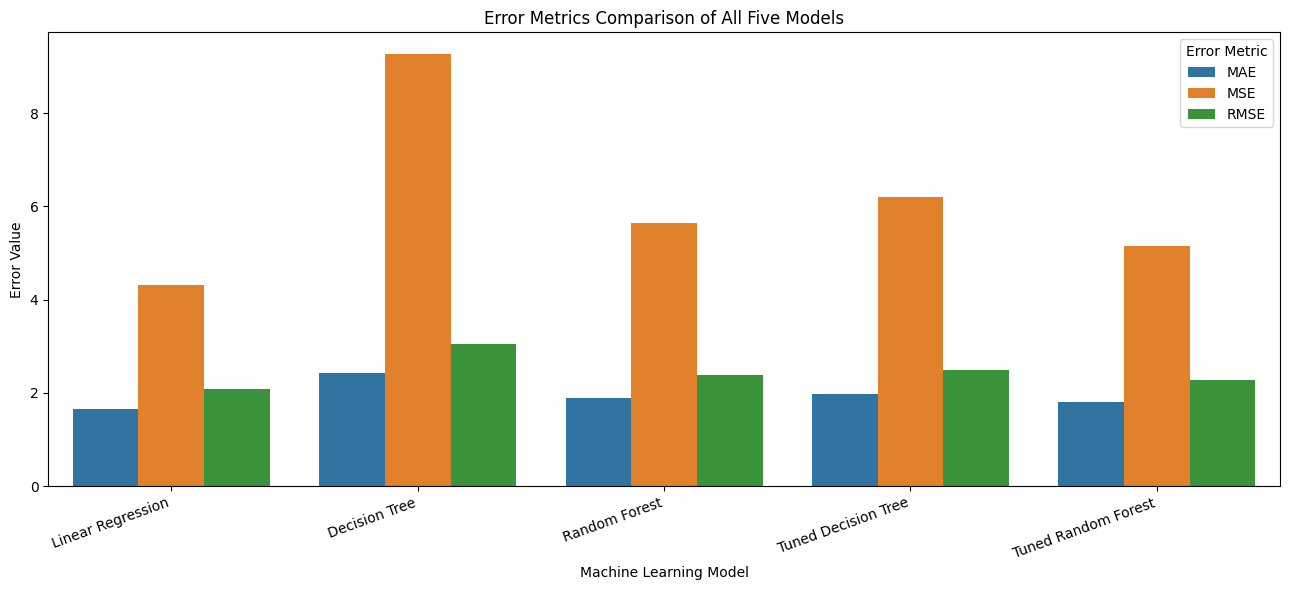

In [35]:
all_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Decision Tree",
        "Tuned Random Forest"
    ],
    "MAE": [1.6470, 2.4196, 1.8975, 1.9802, 1.8085],
    "MSE": [4.3059, 9.2662, 5.6320, 6.1916, 5.1586],
    "RMSE": [2.0751, 3.0440, 2.3732, 2.4883, 2.2713]
})

error_metrics = all_results.melt(
    id_vars="Model",
    var_name="Error Metric",
    value_name="Error Value"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=error_metrics,
    x="Model",
    y="Error Value",
    hue="Error Metric"
)

plt.title("Error Metrics Comparison of All Five Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Error Value")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Error Metric")
plt.tight_layout()
plt.show()

# **5. Conclusion:**
In this task, five machine learning models configurations were evaluated to predict student performance using the Student Performance dataset containing 10,000 records.

Data preprocessing involved removing 127 duplicate rows, encoding categorical features, scaling numerical features, and splitting the data into training and testing sets.

Linear Regression performed best, achieving an MAE of 1.6470, RMSE of 2.0751, and R² score of 0.9884. Hyperparameter tuning improved both Decision Tree and Random Forest models, but neither outperformed Linear Regression.

Therefore, Linear Regression is recommended due to its high accuracy, low prediction errors, and fast training time.